<a href="https://colab.research.google.com/github/jheesus9777-cmyk/petstock-pro/blob/main/01_Codigo_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
departamentos <- c(
  "Finanzas",
  "Recursos Humanos",
  "Operaciones",
  "Tecnologia",
  "Administracion"
)

autorizado <- c(
  500000, 350000, 700000, 450000, 300000
)

ampliacion <- c(
  50000, 25000, 100000, 75000, 25000
)

ejercido <- c(
  420000, 310000, 650000, 390000, 270000
)


In [2]:
# 2. VALIDACION DE ENTRADAS

stopifnot(
  length(departamentos) == length(autorizado),
  length(autorizado) == length(ampliacion),
  length(ampliacion) == length(ejercido)
)

stopifnot(
  all(is.finite(autorizado)),
  all(is.finite(ampliacion)),
  all(is.finite(ejercido))
)

stopifnot(
  all(autorizado > 0),
  all(ampliacion >= 0),
  all(ejercido >= 0)
)


# 3. CALCULO DEL PRESUPUESTO ACTUALIZADO

presupuesto_actualizado <- autorizado + ampliacion


# 4. CALCULO DEL SALDO

saldo <- presupuesto_actualizado - ejercido


# 5. CALCULO DE EJECUCION

ejecucion <- (
  ejercido / presupuesto_actualizado
) * 100


# 6. CALCULO DE PARTICIPACION

participacion <- (
  presupuesto_actualizado /
  sum(presupuesto_actualizado)
)


# 7. CALCULO DE DESVIACION

desviacion <- ejercido - presupuesto_actualizado


# 8. CONSTRUCCION DEL REPORTE

reporte <- data.frame(
  departamento = departamentos,
  autorizado = autorizado,
  ampliacion = ampliacion,
  actualizado = presupuesto_actualizado,
  ejercido = ejercido,
  saldo = saldo,
  ejecucion = ejecucion,
  participacion = participacion,
  desviacion = desviacion
)


# 9. CALCULO DE INDICADORES GLOBALES

presupuesto_total <- sum(presupuesto_actualizado)

ejercicio_total <- sum(ejercido)

saldo_total <- sum(saldo)

ejecucion_global <- (
  ejercicio_total / presupuesto_total
) * 100


In [4]:
# Listar todos los objetos en el entorno actual de R
print("Objetos creados:")
print(ls())

# Mostrar el reporte completo para verificar los resultados
if ("reporte" %in% ls()) {
  print("Contenido del reporte:")
  print(reporte)
}

[1] "Objetos creados:"
 [1] "ampliacion"              "autorizado"             
 [3] "departamentos"           "desviacion"             
 [5] "ejecucion"               "ejecucion_global"       
 [7] "ejercicio_total"         "ejercido"               
 [9] "participacion"           "presupuesto_actualizado"
[11] "presupuesto_total"       "reporte"                
[13] "saldo"                   "saldo_total"            
[1] "Contenido del reporte:"
      departamento autorizado ampliacion actualizado ejercido  saldo ejecucion
1         Finanzas     500000      50000      550000   420000 130000  76.36364
2 Recursos Humanos     350000      25000      375000   310000  65000  82.66667
3      Operaciones     700000     100000      800000   650000 150000  81.25000
4       Tecnologia     450000      75000      525000   390000 135000  74.28571
5   Administracion     300000      25000      325000   270000  55000  83.07692
  participacion desviacion
1     0.2135922    -130000
2     0.1456311     -

In [5]:
# 9. CALCULO DE INDICADORES GLOBALES

presupuesto_total <- sum(presupuesto_actualizado)

ejercicio_total <- sum(ejercido)

saldo_total <- sum(saldo)

ejecucion_global <- (
  ejercicio_total / presupuesto_total
) * 100


# 10. IDENTIFICACION DEL DEPARTAMENTO
# CON MAYOR EJECUCION MONETARIA

mayor_ejercicio <- departamentos[
  which.max(ejercido)
]


# 11. IDENTIFICACION DEL DEPARTAMENTO
# CON MAYOR PORCENTAJE DE EJECUCION

mayor_porcentaje <- departamentos[
  which.max(ejecucion)
]


# 12. VALIDACION DE LA IDENTIDAD PRESUPUESTARIA

stopifnot(
  isTRUE(all.equal(
    sum(presupuesto_actualizado),
    sum(ejercido) + sum(saldo)
  ))
)


# 13. PRESENTACION DE RESULTADOS

print(reporte)

cat(
  "\nPRESUPUESTO TOTAL:",
  presupuesto_total
)

cat(
  "\nEJERCICIO TOTAL:",
  ejercicio_total
)

cat(
  "\nSALDO TOTAL:",
  saldo_total
)

cat(
  "\nEJECUCION GLOBAL:",
  round(ejecucion_global, 2),
  "%"
)

cat(
  "\nMAYOR EJERCICIO MONETARIO:",
  mayor_ejercicio
)

cat(
  "\nMAYOR PORCENTAJE DE EJECUCION:",
  mayor_porcentaje
)

      departamento autorizado ampliacion actualizado ejercido  saldo ejecucion
1         Finanzas     500000      50000      550000   420000 130000  76.36364
2 Recursos Humanos     350000      25000      375000   310000  65000  82.66667
3      Operaciones     700000     100000      800000   650000 150000  81.25000
4       Tecnologia     450000      75000      525000   390000 135000  74.28571
5   Administracion     300000      25000      325000   270000  55000  83.07692
  participacion desviacion
1     0.2135922    -130000
2     0.1456311     -65000
3     0.3106796    -150000
4     0.2038835    -135000
5     0.1262136     -55000

PRESUPUESTO TOTAL: 2575000
EJERCICIO TOTAL: 2040000
SALDO TOTAL: 535000
EJECUCION GLOBAL: 79.22 %
MAYOR EJERCICIO MONETARIO: Operaciones
MAYOR PORCENTAJE DE EJECUCION: Administracion

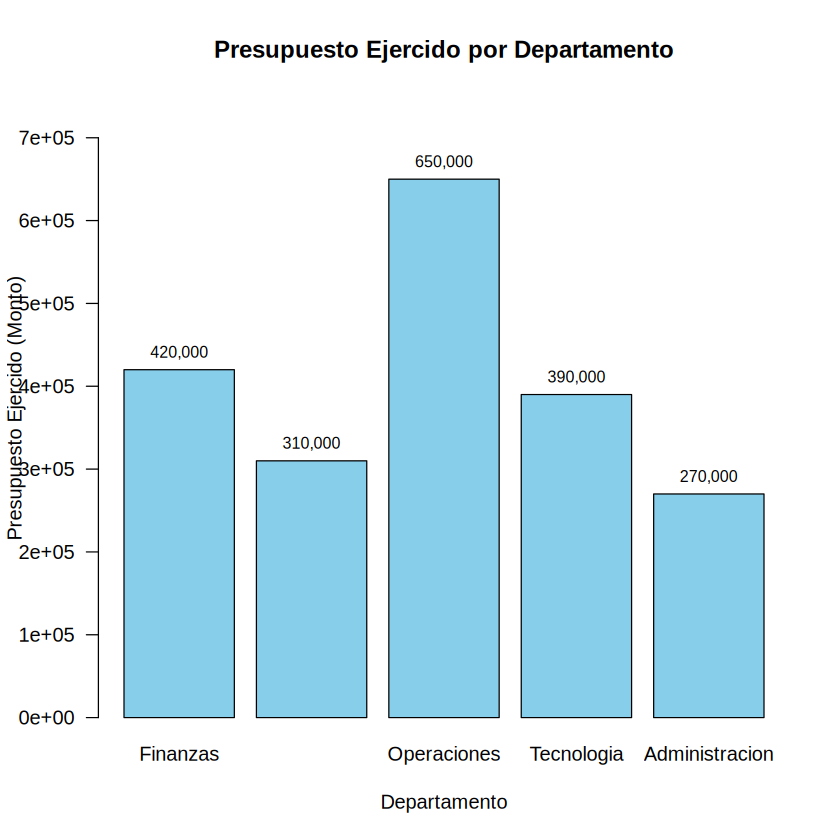

In [6]:
# Crear gráfico de barras para el presupuesto ejercido
barplot(
  height = ejercido,
  names.arg = departamentos,
  col = "skyblue",
  main = "Presupuesto Ejercido por Departamento",
  xlab = "Departamento",
  ylab = "Presupuesto Ejercido (Monto)",
  las = 1,
  ylim = c(0, max(ejercido) * 1.15)
)

# Agregar los valores numéricos encima de cada barra
text(
  x = seq_along(ejercido) * 1.2 - 0.5,
  y = ejercido,
  labels = format(ejercido, big.mark = ","),
  pos = 3,
  cex = 0.8,
  col = "black"
)

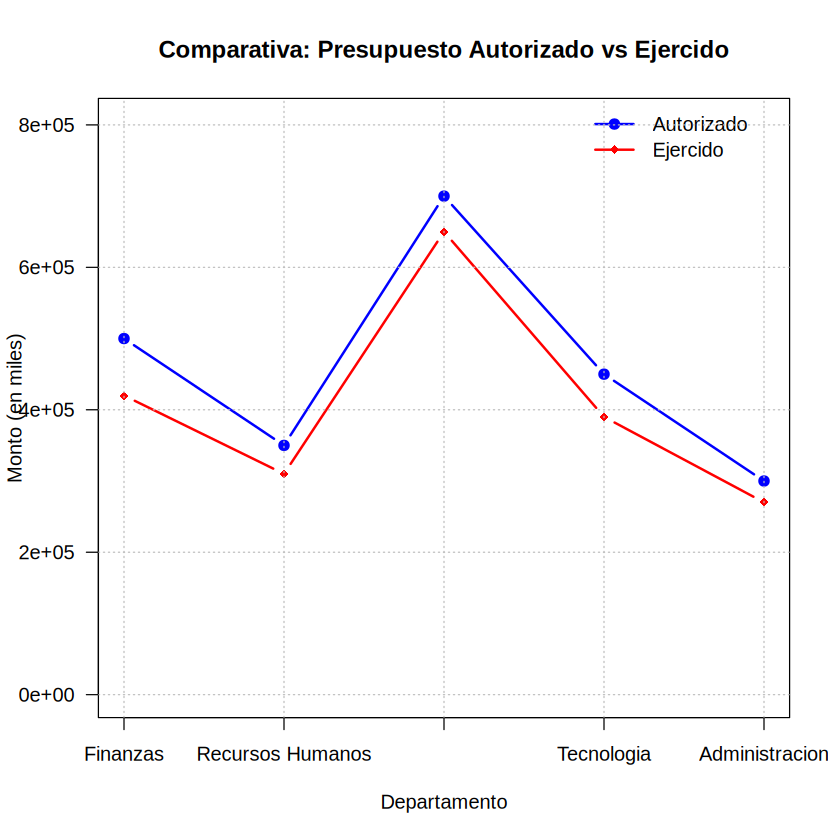

In [7]:
# Configurar el lienzo para el gráfico de líneas
plot(
  x = 1:length(departamentos),
  y = autorizado,
  type = "b",
  col = "blue",
  pch = 19,
  lwd = 2,
  xaxt = "n",
  ylim = c(0, max(c(autorizado, ejercido)) * 1.15),
  main = "Comparativa: Presupuesto Autorizado vs Ejercido",
  xlab = "Departamento",
  ylab = "Monto (en miles)",
  las = 1
)

# Añadir la línea del presupuesto ejercido
lines(
  x = 1:length(departamentos),
  y = ejercido,
  type = "b",
  col = "red",
  pch = 18,
  lwd = 2
)

# Personalizar el eje X con los nombres de los departamentos
axis(
  side = 1,
  at = 1:length(departamentos),
  labels = departamentos
)

# Agregar una leyenda descriptiva
legend(
  "topright",
  legend = c("Autorizado", "Ejercido"),
  col = c("blue", "red"),
  pch = c(19, 18),
  lty = 1,
  lwd = 2,
  bty = "n"
)

# Añadir una cuadrícula de fondo para facilitar la lectura
grid(nx = NULL, ny = NULL, col = "gray", lty = "dotted")

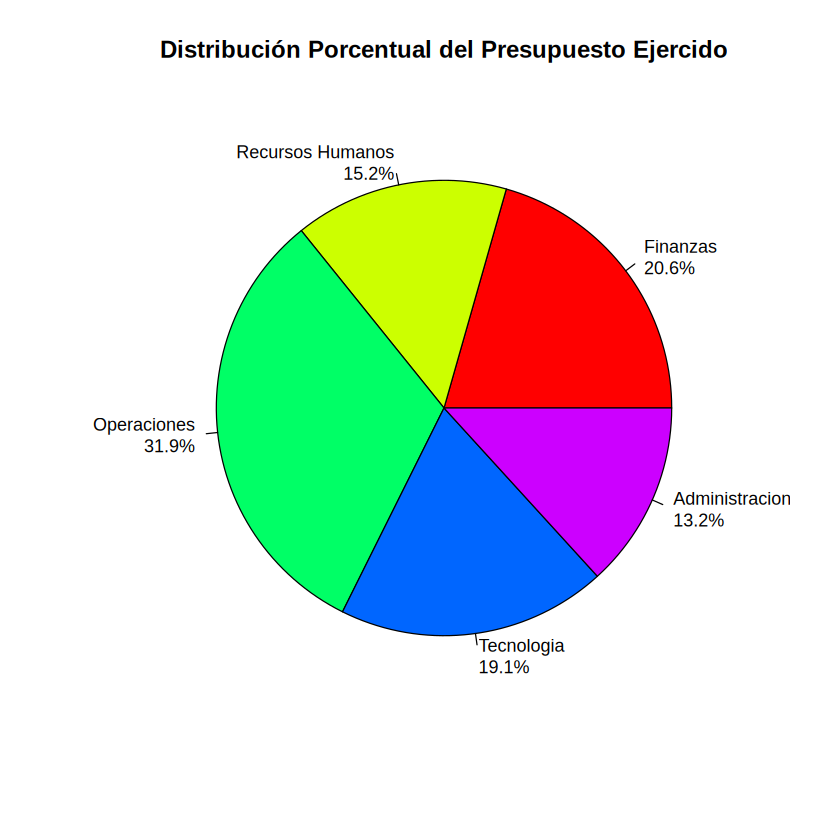

In [8]:
# Calcular los porcentajes del presupuesto ejercido para cada departamento
porcentajes_ejercido <- round((ejercido / sum(ejercido)) * 100, 1)

# Crear etiquetas personalizadas con el nombre del departamento y su porcentaje
etiquetas_pastel <- paste(
  departamentos,
  "\n",
  porcentajes_ejercido,
  "%",
  sep = ""
)

# Generar el gráfico de pastel
pie(
  x = ejercido,
  labels = etiquetas_pastel,
  col = rainbow(length(departamentos)),
  main = "Distribución Porcentual del Presupuesto Ejercido",
  cex = 0.9
)